# HC3 Domain Evaluation

## Research Question

How consistently do our trained AI-text detection models perform across different domains within the HC3 dataset?

## Objectives

- Evaluate model performance across Reddit ELI5, Finance, Open QA, Medicine, and Wiki CS/AI.
- Compare accuracy, macro-F1, human recall, AI recall, and human false-positive rates.
- Identify domains where model performance declines.
- Investigate whether TF-IDF, embedding-based, and transformer-based models exhibit different patterns across domains.

All models will be evaluated using the original held-out HC3 test set and their existing decision rules. No retraining or threshold optimization will be performed.

## Imports, paths, and test data

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load HC3 test data
test = pd.read_csv("../../data/processed/test.csv")

print(f"Test samples: {len(test):,}")
print(f"Columns: {test.columns.tolist()}")

display(test.head(3))

Test samples: 12,632
Columns: ['id', 'question', 'source', 'text', 'label', 'target']


,id,question,source,text,label,target
0,1,"If salt is so bad for cars , why do we use it ...",reddit_eli5,salt is good for not dying in car crashes and ...,human,0
1,1,"If salt is so bad for cars , why do we use it ...",reddit_eli5,"In Minnesota and North Dakota, they tend to us...",human,0
2,1,"If salt is so bad for cars , why do we use it ...",reddit_eli5,"Used to work in the salt industry ( yes, it's ...",human,0


## Explore domain distribution

In [29]:
# Count human (0) and AI (1) responses by source
domain_counts = pd.crosstab(
    test["source"],
    test["target"]
)

# Rename columns for readability
domain_counts = domain_counts.rename(
    columns={0: "Human", 1: "AI"}
)

domain_counts["Total"] = domain_counts.sum(axis=1)

display(domain_counts)

target,Human,AI,Total
source,,,
finance,590,693,1283
medicine,187,201,388
open_qa,178,532,710
reddit_eli5,7497,2500,9997
wiki_csai,127,127,254


## Visualize the domain distribution

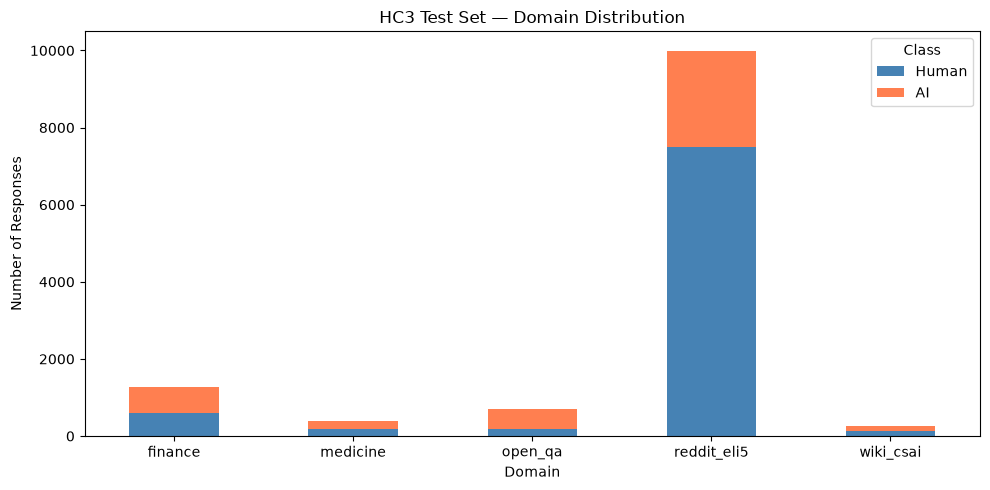

In [30]:
# Plot human and AI counts by domain
ax = domain_counts[["Human", "AI"]].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["steelblue", "coral"]
)

ax.set_title("HC3 Test Set — Domain Distribution")
ax.set_xlabel("Domain")
ax.set_ylabel("Number of Responses")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class")

plt.tight_layout()
plt.show()

## Set up model directories

In [31]:
from pathlib import Path

# Model directories
TFIDF_DIR = Path("../../models/tfidf")
EMBEDDINGS_DIR = Path("../../models/embeddings")

## Load the TF-IDF vectorizer and transform the test data

In [32]:
import joblib

# Load the original fitted TF-IDF vectorizer
vectorizer = joblib.load(
    TFIDF_DIR / "tfidf_vectorizer.joblib"
)

# Transform HC3 test text using the existing vocabulary
X_test_tfidf = vectorizer.transform(
    test["text"].fillna("")
)

y_test = test["target"].to_numpy()

print("TF-IDF feature matrix:", X_test_tfidf.shape)
print("Target labels:", y_test.shape)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


TF-IDF feature matrix: (12632, 100000)
Target labels: (12632,)


## Evaluate TF-IDF Logistic Regression by domain

In [33]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

# Load the trained classifier
lr_bundle = joblib.load(
    TFIDF_DIR / "logistic_regression.joblib"
)

lr = lr_bundle["classifier"]

# Confirm the expected number of features
assert lr.n_features_in_ == X_test_tfidf.shape[1]

# Generate predictions using the original decision rule
lr_predictions = lr.predict(X_test_tfidf)

# Combine predictions with domain labels
lr_results = test[["source", "target"]].copy()
lr_results["prediction"] = lr_predictions

# Calculate metrics for each domain
domain_metrics = []

for source, group in lr_results.groupby("source"):
    y_true = group["target"]
    y_pred = group["prediction"]

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    domain_metrics.append({
        "domain": source,
        "samples": len(group),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "human_recall": tn / (tn + fp),
        "ai_recall": tp / (tp + fn),
        "human_fpr": fp / (tn + fp)
    })

lr_domain_metrics = pd.DataFrame(domain_metrics)

display(
    lr_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,finance,1283,98.83%,0.9882,98.31%,99.28%,1.69%
1,medicine,388,99.74%,0.9974,100.00%,99.50%,0.00%
2,open_qa,710,93.80%,0.9201,92.70%,94.17%,7.30%
3,reddit_eli5,9997,99.20%,0.9893,99.44%,98.48%,0.56%
4,wiki_csai,254,91.73%,0.9172,87.40%,96.06%,12.60%


## Evaluate TF-IDF Linear SVM by domain

In [34]:
def evaluate_domains(model_name, predictions):
    results = test[["source", "target"]].copy()
    results["prediction"] = predictions

    metrics = []

    for source, group in results.groupby("source"):
        y_true = group["target"]
        y_pred = group["prediction"]

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        metrics.append({
            "model": model_name,
            "domain": source,
            "samples": len(group),
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "human_recall": tn / (tn + fp),
            "ai_recall": tp / (tp + fn),
            "human_fpr": fp / (tn + fp)
        })

    return pd.DataFrame(metrics)


# Load the trained Linear SVM
svm_bundle = joblib.load(TFIDF_DIR / "linear_svm_model.joblib")
svm = svm_bundle["classifier"]

assert svm.n_features_in_ == X_test_tfidf.shape[1]

svm_predictions = svm.predict(X_test_tfidf)

# Evaluate both TF-IDF classifiers
lr_domain_metrics["model"] = "TF-IDF Logistic Regression"

svm_domain_metrics = evaluate_domains(
    "TF-IDF Linear SVM",
    svm_predictions
)

display(
    svm_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LinearSVC from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,TF-IDF Linear SVM,finance,1283,99.06%,0.9906,98.81%,99.28%,1.19%
1,TF-IDF Linear SVM,medicine,388,99.74%,0.9974,100.00%,99.50%,0.00%
2,TF-IDF Linear SVM,open_qa,710,94.37%,0.9274,93.82%,94.55%,6.18%
3,TF-IDF Linear SVM,reddit_eli5,9997,99.33%,0.9911,99.59%,98.56%,0.41%
4,TF-IDF Linear SVM,wiki_csai,254,91.73%,0.9172,87.40%,96.06%,12.60%


## Evaluate TF-IDF FFNN by domain

In [35]:
import json
from tensorflow import keras

# Load original trained neural network
ffnn = keras.models.load_model(
    TFIDF_DIR / "feedforward_neural_network.keras",
    compile=False
)

# Load original decision threshold
meta_path = TFIDF_DIR / "feedforward_neural_network_metadata.json"

meta = json.loads(meta_path.read_text())
threshold = float(meta.get("threshold", 0.5))

# Generate AI scores in batches
scores = []

for start in range(0, X_test_tfidf.shape[0], 256):
    batch = X_test_tfidf[start:start + 256].toarray()
    batch_scores = ffnn.predict(batch, verbose=0).ravel()
    scores.extend(batch_scores)

scores = np.array(scores)

# Apply original threshold
ffnn_predictions = (scores >= threshold).astype(int)

# Evaluate across domains
ffnn_domain_metrics = evaluate_domains(
    "TF-IDF FFNN",
    ffnn_predictions
)

print("Original threshold:", threshold)

display(
    ffnn_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

Original threshold: 0.5


,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,TF-IDF FFNN,finance,1283,99.53%,0.9953,99.32%,99.71%,0.68%
1,TF-IDF FFNN,medicine,388,100.00%,1.0000,100.00%,100.00%,0.00%
2,TF-IDF FFNN,open_qa,710,93.24%,0.9132,92.13%,93.61%,7.87%
3,TF-IDF FFNN,reddit_eli5,9997,99.39%,0.9919,99.55%,98.92%,0.45%
4,TF-IDF FFNN,wiki_csai,254,92.91%,0.9290,88.98%,96.85%,11.02%


## Evaluate TF-IDF Multinomial Naive Bayes by domain

In [36]:
# Load Multinomial Naive Bayes
nb_bundle = joblib.load(
    TFIDF_DIR / "multinomial_naive_bayes.joblib"
)

nb = nb_bundle["classifier"] if isinstance(nb_bundle, dict) else nb_bundle

# Verify feature dimensions
assert nb.n_features_in_ == X_test_tfidf.shape[1]

# Generate predictions
nb_predictions = nb.predict(X_test_tfidf)

# Evaluate across domains
nb_domain_metrics = evaluate_domains(
    "TF-IDF Multinomial NB",
    nb_predictions
)

display(
    nb_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MultinomialNB from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,TF-IDF Multinomial NB,finance,1283,96.34%,0.9629,92.03%,100.00%,7.97%
1,TF-IDF Multinomial NB,medicine,388,99.74%,0.9974,99.47%,100.00%,0.53%
2,TF-IDF Multinomial NB,open_qa,710,87.89%,0.8324,70.22%,93.80%,29.78%
3,TF-IDF Multinomial NB,reddit_eli5,9997,95.62%,0.9391,99.09%,85.20%,0.91%
4,TF-IDF Multinomial NB,wiki_csai,254,78.35%,0.7758,59.84%,96.85%,40.16%


In [19]:
# Load K-Nearest Neighbors
knn_bundle = joblib.load(
    TFIDF_DIR / "knn_model.joblib"
)

# Extract trained KNN model and its saved vectorizer
knn = knn_bundle["model"]
knn_vectorizer = knn_bundle["vectorizer"]

print("KNN model:", type(knn).__name__)
print("KNN vectorizer:", type(knn_vectorizer).__name__)
print("Expected features:", knn.n_features_in_)
print("Current TF-IDF features:", X_test_tfidf.shape[1])

# Verify feature dimensions
assert knn.n_features_in_ == X_test_tfidf.shape[1]

# Apply KNN's original decision threshold
knn_threshold = knn_bundle["config"]["threshold"]

knn_scores = knn.predict_proba(X_test_tfidf)[:, 1]
knn_predictions = (knn_scores >= knn_threshold).astype(int)

knn_domain_metrics = evaluate_domains(
    "TF-IDF KNN", knn_predictions
)

display(
    knn_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator KNeighborsClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


KNN model: KNeighborsClassifier
KNN vectorizer: str
Expected features: 100000
Current TF-IDF features: 100000


,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,TF-IDF KNN,finance,1283,80.05%,0.7835,56.61%,100.00%,43.39%
1,TF-IDF KNN,medicine,388,97.68%,0.9767,95.19%,100.00%,4.81%
2,TF-IDF KNN,open_qa,710,87.89%,0.8350,72.47%,93.05%,27.53%
3,TF-IDF KNN,reddit_eli5,9997,95.80%,0.9440,97.17%,91.68%,2.83%
4,TF-IDF KNN,wiki_csai,254,75.98%,0.7480,54.33%,97.64%,45.67%


## Compare all five TF-IDF models

In [37]:
# Combine all five TF-IDF domain evaluations
tfidf_domain_comparison = pd.concat([
    lr_domain_metrics,
    svm_domain_metrics,
    ffnn_domain_metrics,
    nb_domain_metrics,
    knn_domain_metrics
], ignore_index=True)

# Compare macro F1 across domains
f1_comparison = tfidf_domain_comparison.pivot(
    index="domain",
    columns="model",
    values="macro_f1"
)

display(f1_comparison.style.format("{:.4f}"))

model,TF-IDF FFNN,TF-IDF KNN,TF-IDF Linear SVM,TF-IDF Logistic Regression,TF-IDF Multinomial NB
domain,,,,,
finance,0.9953,0.7835,0.9906,0.9882,0.9629
medicine,1.0000,0.9767,0.9974,0.9974,0.9974
open_qa,0.9132,0.8350,0.9274,0.9201,0.8324
reddit_eli5,0.9919,0.9440,0.9911,0.9893,0.9391
wiki_csai,0.9290,0.7480,0.9172,0.9172,0.7758


##  Human false-positive rates by domain

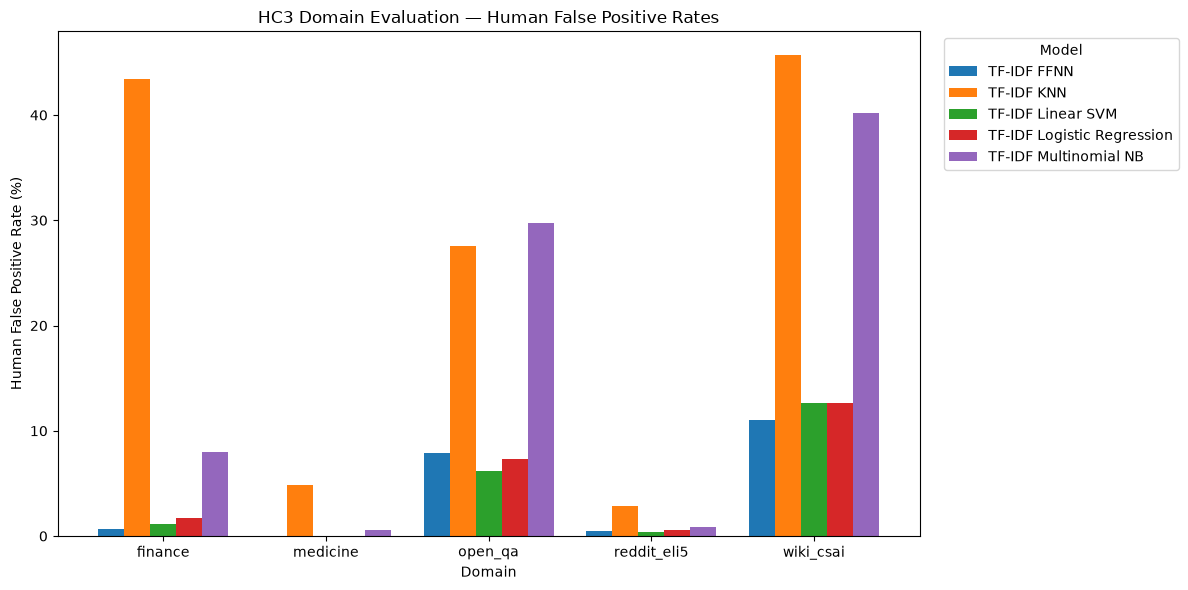

In [38]:
fpr_comparison = tfidf_domain_comparison.pivot(
    index="domain",
    columns="model",
    values="human_fpr"
)

ax = (fpr_comparison * 100).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("HC3 Domain Evaluation — Human False Positive Rates")
ax.set_xlabel("Domain")
ax.set_ylabel("Human False Positive Rate (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Load saved test embeddings

In [39]:
X_test_embeddings = np.load(
    EMBEDDINGS_DIR / "test_embeddings.npy"
)

print("Embedding shape:", X_test_embeddings.shape)
print("Test labels:", y_test.shape)

assert len(X_test_embeddings) == len(y_test)

Embedding shape: (12632, 384)
Test labels: (12632,)


## Load embedding-based Logistic Regression

In [40]:
emb_lr_bundle = joblib.load(
    EMBEDDINGS_DIR / "logistic_regression_embeddings.joblib"
)

print("Artifact type:", type(emb_lr_bundle))

if isinstance(emb_lr_bundle, dict):
    print("Saved keys:", emb_lr_bundle.keys())
else:
    print("Model:", type(emb_lr_bundle).__name__)

Artifact type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Model: LogisticRegression


/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## Evaluate embedding Logistic Regression by domain

In [41]:
# Use the loaded Logistic Regression model
emb_lr = emb_lr_bundle

# Verify embedding dimensions
assert emb_lr.n_features_in_ == X_test_embeddings.shape[1]

# Generate predictions
emb_lr_predictions = emb_lr.predict(X_test_embeddings)

# Evaluate across domains
emb_lr_domain_metrics = evaluate_domains(
    "Embedding Logistic Regression",
    emb_lr_predictions
)

display(
    emb_lr_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,Embedding Logistic Regression,finance,1283,86.28%,0.8601,78.64%,92.78%,21.36%
1,Embedding Logistic Regression,medicine,388,72.42%,0.7117,53.48%,90.05%,46.52%
2,Embedding Logistic Regression,open_qa,710,74.79%,0.7056,73.60%,75.19%,26.40%
3,Embedding Logistic Regression,reddit_eli5,9997,87.74%,0.8472,88.10%,86.64%,11.90%
4,Embedding Logistic Regression,wiki_csai,254,64.96%,0.6349,44.88%,85.04%,55.12%


## Load embedding-based Linear SVM by domain

In [42]:
# Load embedding-based Linear SVM
emb_svm_bundle = joblib.load(
    EMBEDDINGS_DIR / "linear_svm_embeddings.joblib"
)

print("Artifact type:", type(emb_svm_bundle))

if isinstance(emb_svm_bundle, dict):
    print("Saved keys:", emb_svm_bundle.keys())
else:
    print("Model:", type(emb_svm_bundle).__name__)

Artifact type: <class 'sklearn.svm._classes.LinearSVC'>
Model: LinearSVC


/opt/homebrew/Caskroom/miniconda/base/envs/chewy-roberta/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LinearSVC from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## Evaluate embedding-based Linear SVM by domain

In [43]:
# Use the saved Linear SVM
emb_svm = emb_svm_bundle

# Verify embedding dimensions
assert emb_svm.n_features_in_ == X_test_embeddings.shape[1]

# Generate predictions
emb_svm_predictions = emb_svm.predict(X_test_embeddings)

# Evaluate across domains
emb_svm_domain_metrics = evaluate_domains(
    "Embedding Linear SVM",
    emb_svm_predictions
)

display(
    emb_svm_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,Embedding Linear SVM,finance,1283,87.37%,0.8715,80.68%,93.07%,19.32%
1,Embedding Linear SVM,medicine,388,73.45%,0.7237,55.61%,90.05%,44.39%
2,Embedding Linear SVM,open_qa,710,77.75%,0.7322,73.03%,79.32%,26.97%
3,Embedding Linear SVM,reddit_eli5,9997,87.91%,0.8489,88.40%,86.44%,11.60%
4,Embedding Linear SVM,wiki_csai,254,63.78%,0.6179,40.94%,86.61%,59.06%


## Load embedding-based FFNN

In [45]:
# Load embedding FFNN
emb_ffnn = keras.models.load_model(
    EMBEDDINGS_DIR / "feedforward_neural_network_embeddings.keras",
    compile=False
)

print("Model input shape:", emb_ffnn.input_shape)

Model input shape: (None, 384)


## Evaluate embedding FFNN by domain

In [46]:
# Generate embedding FFNN predictions
emb_ffnn_scores = emb_ffnn.predict(
    X_test_embeddings,
    batch_size=256,
    verbose=0
).ravel()

# Apply standard classification threshold
emb_ffnn_predictions = (emb_ffnn_scores >= 0.5).astype(int)

# Evaluate across domains
emb_ffnn_domain_metrics = evaluate_domains(
    "Embedding FFNN",
    emb_ffnn_predictions
)

display(
    emb_ffnn_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,Embedding FFNN,finance,1283,92.99%,0.9293,91.36%,94.37%,8.64%
1,Embedding FFNN,medicine,388,90.46%,0.9044,88.77%,92.04%,11.23%
2,Embedding FFNN,open_qa,710,80.56%,0.7641,76.97%,81.77%,23.03%
3,Embedding FFNN,reddit_eli5,9997,93.77%,0.9190,94.53%,91.48%,5.47%
4,Embedding FFNN,wiki_csai,254,72.83%,0.7225,58.27%,87.40%,41.73%


## Compare all three embedding models

In [47]:
# Combine the three embedding-based evaluations
embedding_domain_comparison = pd.concat([
    emb_lr_domain_metrics,
    emb_svm_domain_metrics,
    emb_ffnn_domain_metrics
], ignore_index=True)

# Compare macro F1 across domains
embedding_f1_comparison = embedding_domain_comparison.pivot(
    index="domain",
    columns="model",
    values="macro_f1"
)

display(embedding_f1_comparison.style.format("{:.4f}"))

model,Embedding FFNN,Embedding Linear SVM,Embedding Logistic Regression
domain,,,
finance,0.9293,0.8715,0.8601
medicine,0.9044,0.7237,0.7117
open_qa,0.7641,0.7322,0.7056
reddit_eli5,0.9190,0.8489,0.8472
wiki_csai,0.7225,0.6179,0.6349


## Embedding models: Human false-positive rates

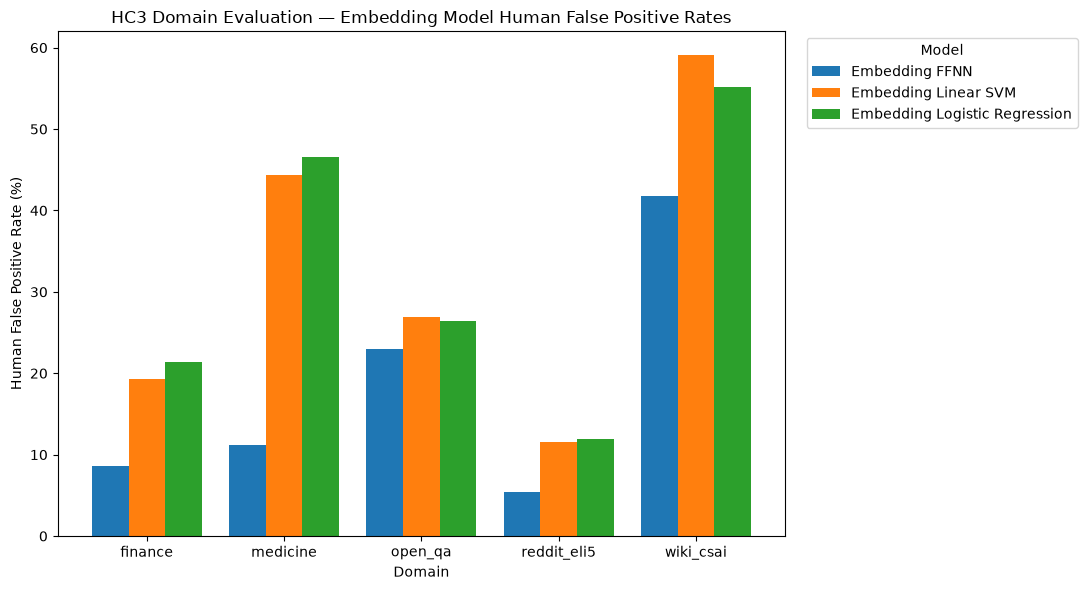

In [48]:
# Compare human false-positive rates
embedding_fpr_comparison = embedding_domain_comparison.pivot(
    index="domain",
    columns="model",
    values="human_fpr"
)

ax = (embedding_fpr_comparison * 100).plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("HC3 Domain Evaluation — Embedding Model Human False Positive Rates")
ax.set_xlabel("Domain")
ax.set_ylabel("Human False Positive Rate (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Import and load RoBERTa

In [49]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ROBERTA_MODEL_ID = "akeight/spot-the-bot-roberta"

# Select available hardware
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Load published RoBERTa checkpoint
roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL_ID)
roberta_model = AutoModelForSequenceClassification.from_pretrained(ROBERTA_MODEL_ID)

roberta_model = roberta_model.to(device)
roberta_model.eval()

print("Loaded RoBERTa from:", ROBERTA_MODEL_ID)
print("Device:", device)
print("Number of labels:", roberta_model.config.num_labels)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded RoBERTa from: akeight/spot-the-bot-roberta
Device: mps
Number of labels: 2


## Prepare RoBERTa inference

In [13]:
import torch

# Use Apple Silicon GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

roberta_model = roberta_model.to(device)
roberta_model.eval()

MAX_LENGTH = 384

print("Device:", device)
print("Test samples:", len(test))
print("Max token length:", MAX_LENGTH)

Device: mps
Test samples: 12632
Max token length: 384


## Generate RoBERTa predictions

In [50]:
from tqdm.auto import tqdm

roberta_predictions = []

batch_size = 16

with torch.inference_mode():
    for start in tqdm(range(0, len(test), batch_size)):
        texts = test["text"].iloc[start:start + batch_size].fillna("").tolist()

        inputs = roberta_tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        outputs = roberta_model(**inputs)

        predictions = outputs.logits.argmax(dim=1)
        roberta_predictions.extend(predictions.cpu().numpy())

roberta_predictions = np.array(roberta_predictions)

print("Predictions generated:", len(roberta_predictions))
print("Predicted Human:", (roberta_predictions == 0).sum())
print("Predicted AI:", (roberta_predictions == 1).sum())

  0%|          | 0/790 [00:00<?, ?it/s]

Predictions generated: 12632
Predicted Human: 8489
Predicted AI: 4143


## Evaluate RoBERTa by domain

In [51]:
# Evaluate RoBERTa across all five HC3 domains
roberta_domain_metrics = evaluate_domains(
    "RoBERTa",
    roberta_predictions
)

display(
    roberta_domain_metrics.style.format({
        "accuracy": "{:.2%}",
        "macro_f1": "{:.4f}",
        "human_recall": "{:.2%}",
        "ai_recall": "{:.2%}",
        "human_fpr": "{:.2%}"
    })
)

,model,domain,samples,accuracy,macro_f1,human_recall,ai_recall,human_fpr
0,RoBERTa,finance,1283,98.91%,0.9890,97.63%,100.00%,2.37%
1,RoBERTa,medicine,388,99.74%,0.9974,99.47%,100.00%,0.53%
2,RoBERTa,open_qa,710,99.58%,0.9944,98.88%,99.81%,1.12%
3,RoBERTa,reddit_eli5,9997,99.52%,0.9936,99.36%,100.00%,0.64%
4,RoBERTa,wiki_csai,254,89.76%,0.8966,79.53%,100.00%,20.47%


## Compare all nine models

In [52]:
all_domain_metrics = pd.concat(
    [
        tfidf_domain_comparison,
        embedding_domain_comparison,
        roberta_domain_metrics
    ],
    ignore_index=True
)

all_f1_comparison = all_domain_metrics.pivot(
    index="domain",
    columns="model",
    values="macro_f1"
)

display(
    all_f1_comparison.style
    .format("{:.4f}")
    .highlight_max(
        axis=1,
        props="background-color: #166534; color: white; font-weight: bold;"
    )
)

model,Embedding FFNN,Embedding Linear SVM,Embedding Logistic Regression,RoBERTa,TF-IDF FFNN,TF-IDF KNN,TF-IDF Linear SVM,TF-IDF Logistic Regression,TF-IDF Multinomial NB
domain,,,,,,,,,
finance,0.9293,0.8715,0.8601,0.9890,0.9953,0.7835,0.9906,0.9882,0.9629
medicine,0.9044,0.7237,0.7117,0.9974,1.0000,0.9767,0.9974,0.9974,0.9974
open_qa,0.7641,0.7322,0.7056,0.9944,0.9132,0.8350,0.9274,0.9201,0.8324
reddit_eli5,0.9190,0.8489,0.8472,0.9936,0.9919,0.9440,0.9911,0.9893,0.9391
wiki_csai,0.7225,0.6179,0.6349,0.8966,0.9290,0.7480,0.9172,0.9172,0.7758


## Macro F1 & human false-positive rate heatmap

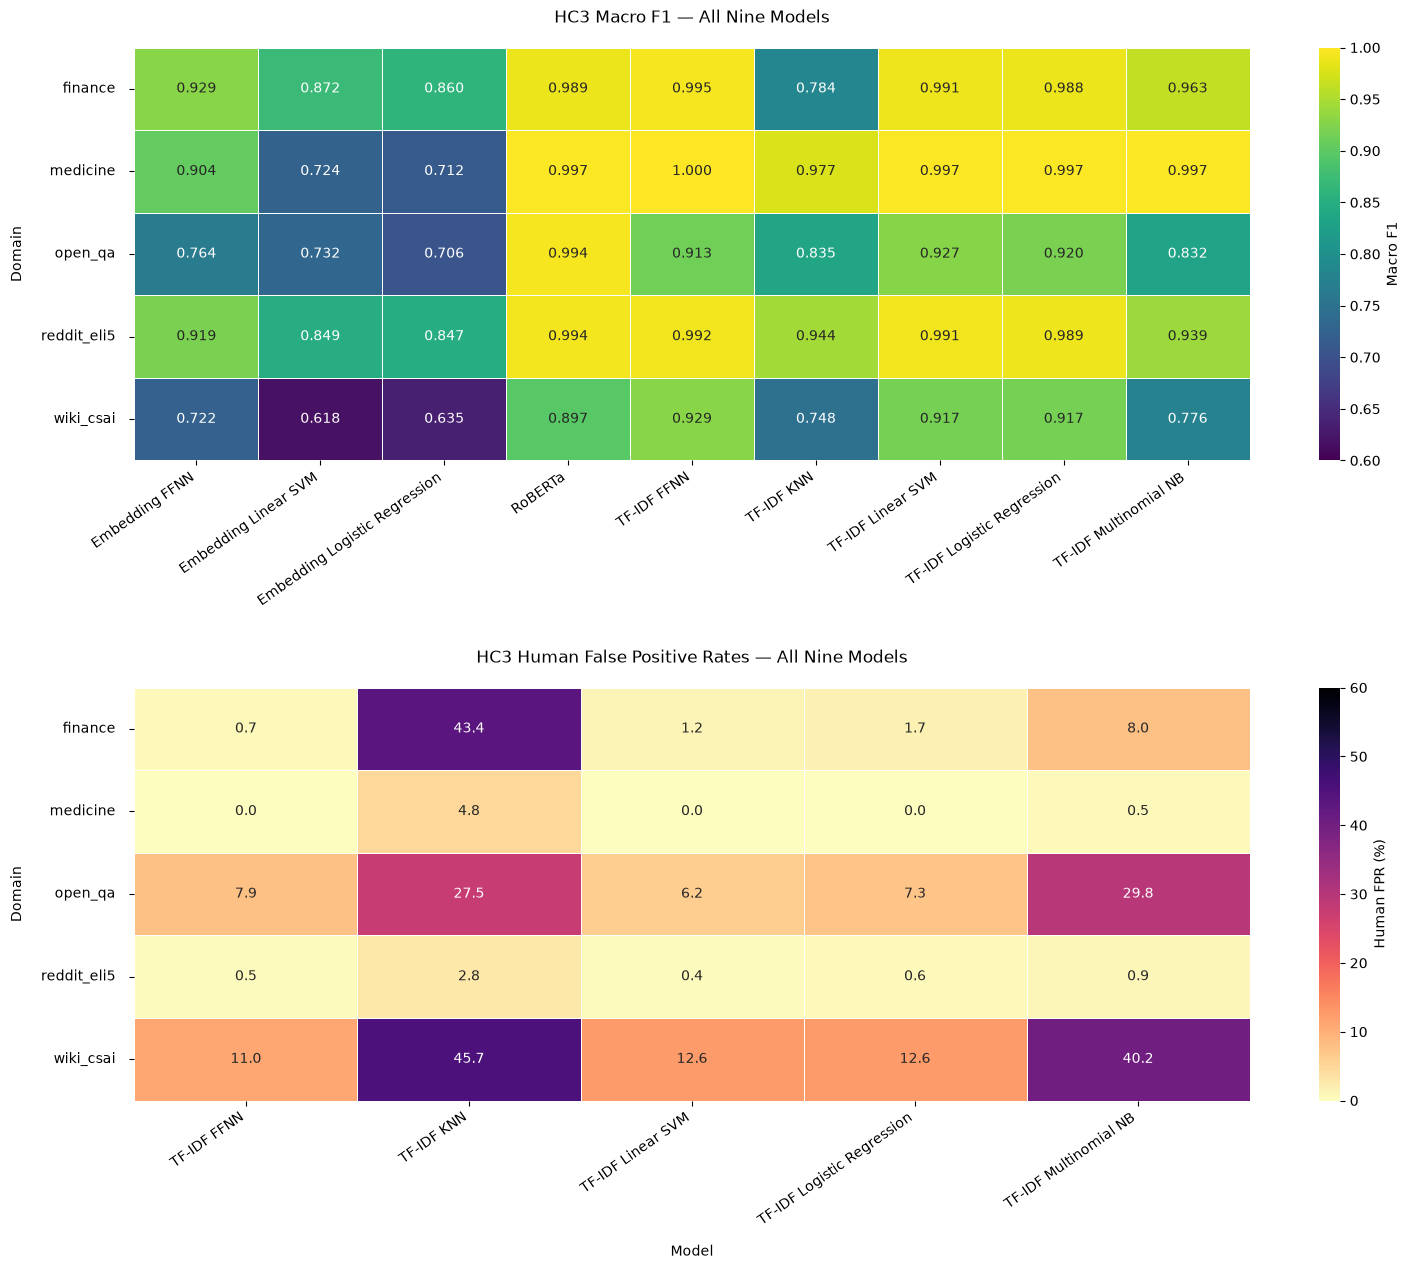

In [54]:
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(17, 13))

sns.heatmap(
    all_f1_comparison,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0.6,
    vmax=1.0,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Macro F1"}
)

axes[0].set_title("HC3 Macro F1 — All Nine Models", pad=18)
axes[0].set_ylabel("Domain", labelpad=12)
axes[0].set_xlabel("")
axes[0].tick_params(axis="y", labelrotation=0, pad=10)

sns.heatmap(
    fpr_comparison * 100,
    annot=True,
    fmt=".1f",
    cmap="magma_r",
    vmin=0,
    vmax=60,
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Human FPR (%)"}
)

axes[1].set_title("HC3 Human False Positive Rates — All Nine Models", pad=18)
axes[1].set_ylabel("Domain", labelpad=12)
axes[1].set_xlabel("Model", labelpad=12)
axes[1].tick_params(axis="y", labelrotation=0, pad=10)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

plt.subplots_adjust(
    left=0.14,
    right=0.96,
    top=0.94,
    bottom=0.13,
    hspace=0.55
)

plt.show()